# STM simulator demo

Exercises `mexpsimu`'s STM path (`STMMicroscope` / `STMScanDataset`) end to
end against the bundled `large_area` preset (`.sxm` + `.3ds` of the same
frame, `mexpsimu/data/stm_data/large_area/sidpy/`), in three variants:

- **combined** -- the preset itself: `.sxm` image channels plus the `.3ds`
  grid `Topography`;
- **`.3ds` only** -- the same data without the `.sxm` channels (what
  `convert_nanonis_folder` writes for a folder with no `.sxm`): the grid
  `Topography` is the image;
- **no topography at all** -- spectroscopy only, which falls back to the
  synthesized `current_avg` image.

The last two are written to temporary files from the preset.

Run once from the project root:

```bash
pip install -e .
```

then start this notebook from the same environment -- `import mexpsimu`
below resolves to the installed (editable) package.

In [1]:
import tempfile
import warnings
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np

import mexpsimu
from mexpsimu.nsid_io import open_readonly, read_channels, write_channels

warnings.filterwarnings("ignore", category=FutureWarning, module="pyNSID")

print("mexpsimu", mexpsimu.__version__, "from", mexpsimu.__file__)
print("large_area preset:", mexpsimu.resolve_stm_dataset_path("large_area").relative_to(mexpsimu.default_stm_data_dir()))

mexpsimu 0.1.0 from /Users/ggn/1py_scripts/Aecroscopy_hackathon/MExpSim/mexpsimu_stm/mexpsimu/__init__.py
large_area preset: large_area/sidpy/EuZn2As2008_EnZn2As2122_combined_sd.h5


In [2]:
def extent(channel):
    """imshow extent from a Channel's (Y, X) axes, in nm."""
    y, x = channel.axes[0].values, channel.axes[1].values
    return [x.min(), x.max(), y.min(), y.max()]


def write_variant(name, topography_channels):
    """Copy large_area's spectroscopy section, plus only the named
    topography channels, into a temporary .h5 file."""
    path = Path(tempfile.gettempdir()) / f"mexpsimu_demo_{name}_sd.h5"
    with open_readonly(mexpsimu.resolve_stm_dataset_path("large_area")) as src, h5py.File(path, "w") as out:
        write_channels(read_channels(src["spectroscopy"]), out.create_group("spectroscopy"))
        topo = {k: v for k, v in read_channels(src["topography"]).items() if k in topography_channels}
        if topo:
            write_channels(topo, out.create_group("topography"))
    return path

## `.sxm` + `.3ds` combined (`large_area`)

In [3]:
scope = mexpsimu.STMMicroscope("large_area")
print(scope)
print("has_topography:", scope.has_topography)
print("image channels:", scope.list_channels())
print("spectroscopy channels:", scope.list_spectroscopy_channels())

STMMicroscope(dataset='EuZn2As2008_EnZn2As2122_combined_sd', has_topography=True, spectroscopy_shape=(180, 180), measurement_noise=0.0, position=STMTipPosition(row=90, col=90, x_nm=125.0, y_nm=125.0))
has_topography: True
image channels: ['Current backward', 'Current forward', 'LIX_1_omega backward', 'LIX_1_omega forward', 'LIY_1_omega backward', 'LIY_1_omega forward', 'Topography', 'Z backward', 'Z forward']
spectroscopy channels: ['Current', 'LIX 1 omega', 'LIY 1 omega']


`scan_image()` returns the `.sxm` `Z forward` by default;
`scan_image("Topography")` returns the `.3ds` grid's own Z map (coarser, same
frame). The tip is addressed on the spectroscopy grid.

moved to: STMTipPosition(row=130, col=29, x_nm=40.0, y_nm=180.0)


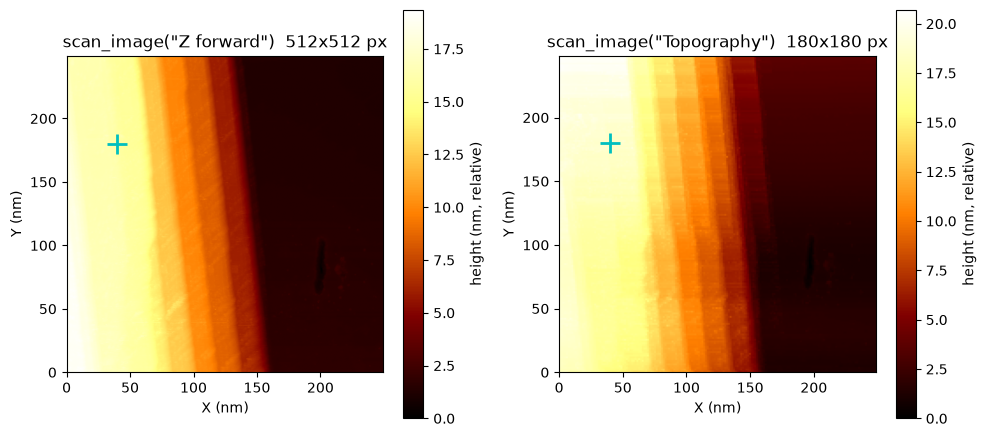

In [4]:
pos = scope.move_tip(40.0, 180.0)  # x, y in nanometers
print("moved to:", pos)

topo_ch = scope.dataset.topography
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, name in zip(axs, [scope.default_image_channel, "Topography"]):
    z = scope.scan_image(name)
    im = ax.imshow((z - np.nanmin(z)) * 1e9, origin="lower", extent=extent(topo_ch[name]), cmap="afmhot")
    ax.plot(pos.x_nm, pos.y_nm, "c+", markersize=14, markeredgewidth=2)
    ax.set_title(f'scan_image("{name}")  {z.shape[1]}x{z.shape[0]} px')
    ax.set_xlabel("X (nm)")
    ax.set_ylabel("Y (nm)")
    fig.colorbar(im, ax=ax, label="height (nm, relative)")
fig.tight_layout()
plt.show()

Interpolated spectrum differs from the nearest grid pixel (130, 29) by at most 11.9% of its peak.


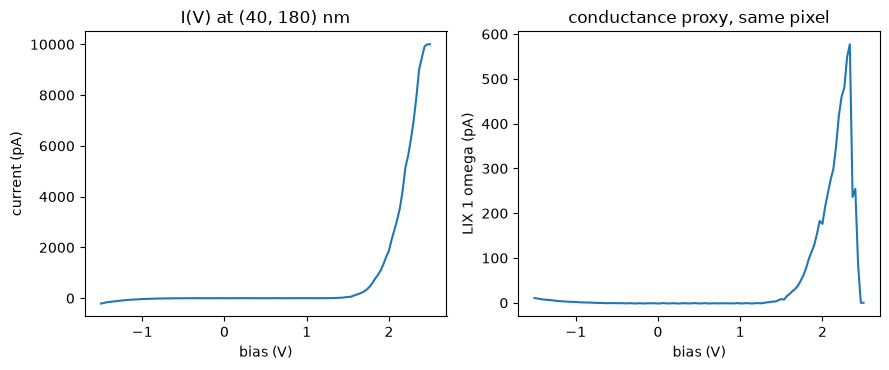

In [5]:
bias, current = scope.spectroscopy()  # default channel: "Current", at the tip position
_, lix = scope.spectroscopy(channel="LIX 1 omega")

# The response is interpolated (bilinear) from the 4 grid points around the tip,
# so it generally differs from the recorded spectrum at the nearest grid pixel.
nearest = scope.dataset.spectroscopy["Current"].data[pos.row, pos.col]
print(f"Interpolated spectrum differs from the nearest grid pixel ({pos.row}, {pos.col}) "
      f"by at most {np.nanmax(np.abs(current - nearest)) / np.nanmax(np.abs(nearest)):.1%} of its peak.")

fig, axs = plt.subplots(1, 2, figsize=(9, 3.8))
axs[0].plot(bias, current * 1e12)
axs[0].set_xlabel("bias (V)")
axs[0].set_ylabel("current (pA)")
axs[0].set_title(f"I(V) at ({pos.x_nm:.0f}, {pos.y_nm:.0f}) nm")
axs[1].plot(bias, lix * 1e12)
axs[1].set_xlabel("bias (V)")
axs[1].set_ylabel("LIX 1 omega (pA)")
axs[1].set_title("conductance proxy, same pixel")
fig.tight_layout()
plt.show()

## `.3ds` only

No `.sxm` scan, but every `.3ds` grid records the Z-controller height at each
pixel, so `has_topography` is `True` and the grid `Topography` is the default
image. Spectra are taken at a few points across the frame.

STMMicroscope(dataset='mexpsimu_demo_3ds_only_sd', has_topography=True, spectroscopy_shape=(180, 180), measurement_noise=0.0, position=STMTipPosition(row=90, col=90, x_nm=125.0, y_nm=125.0))
image channels: ['Topography'] default: Topography


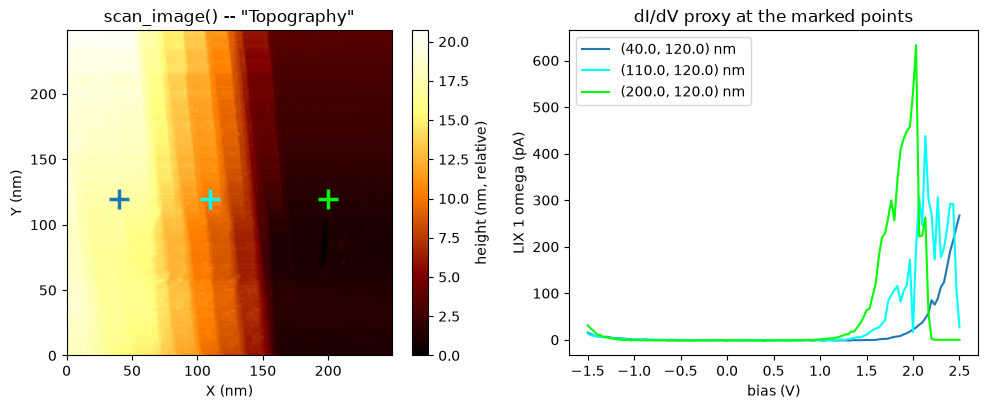

In [6]:
grid_only_path = write_variant("3ds_only", {"Topography"})
grid_scope = mexpsimu.STMMicroscope(grid_only_path)
print(grid_scope)
print("image channels:", grid_scope.list_channels(), "default:", grid_scope.default_image_channel)

z = grid_scope.scan_image()
points_nm = [(40.0, 120.0), (110.0, 120.0), (200.0, 120.0)]  # upper terrace, step region, lower terrace

fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
im = axs[0].imshow((z - np.nanmin(z)) * 1e9, origin="lower",
                   extent=extent(grid_scope.dataset.topography["Topography"]), cmap="afmhot")
fig.colorbar(im, ax=axs[0], label="height (nm, relative)")
axs[0].set_title(f'scan_image() -- "{grid_scope.default_image_channel}"')
axs[0].set_xlabel("X (nm)")
axs[0].set_ylabel("Y (nm)")
for (x, y), color in zip(points_nm, ["tab:blue", "cyan", "lime"]):
    bias, didv = grid_scope.spectroscopy(x, y, channel="LIX 1 omega")
    p = grid_scope.position
    axs[1].plot(bias, didv * 1e12, color=color, label=f"({p.x_nm:.1f}, {p.y_nm:.1f}) nm")
    axs[0].plot(p.x_nm, p.y_nm, "+", color=color, markersize=14, markeredgewidth=2.5)
axs[1].set_xlabel("bias (V)")
axs[1].set_ylabel("LIX 1 omega (pA)")
axs[1].set_title("dI/dV proxy at the marked points")
axs[1].legend()
fig.tight_layout()
plt.show()
grid_only_path.unlink()

## No topography at all -- the `current_avg` fallback

Keep only the `spectroscopy` section, then load it the same way. `has_topography` should be `False`, and the only image
channel the synthesized `current_avg` (the `Current` cube averaged over bias).

has_topography: False
image channels: ['current_avg']
matches manual mean-over-bias: True


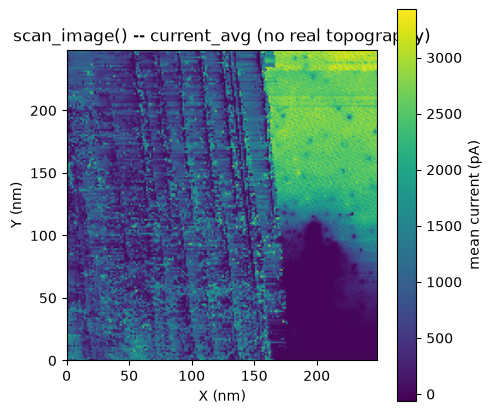

In [7]:
spec_only_path = write_variant("spec_only", set())

no_topo_scope = mexpsimu.STMMicroscope(spec_only_path)
print("has_topography:", no_topo_scope.has_topography)
print("image channels:", no_topo_scope.list_channels())

fallback_img = no_topo_scope.scan_image()
manual_avg = no_topo_scope.dataset.spectroscopy["Current"].data.mean(axis=2)
print("matches manual mean-over-bias:", np.array_equal(fallback_img, manual_avg))

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(fallback_img * 1e12, origin="lower",
               extent=extent(no_topo_scope.dataset.spectroscopy["Current"]), cmap="viridis")
ax.set_title(f"scan_image() -- {no_topo_scope.default_image_channel} (no real topography)")
ax.set_xlabel("X (nm)")
ax.set_ylabel("Y (nm)")
fig.colorbar(im, ax=ax, label="mean current (pA)")
fig.tight_layout()
plt.show()
spec_only_path.unlink()

## Result

`scan_image()`, `move_tip()` and `spectroscopy()` work the same way for
combined `.sxm` + `.3ds` data, `.3ds`-only data, and spectroscopy-only data.
A caller only sees the difference in `list_channels()`, the default image
channel (`Z forward`, then the grid `Topography`, then `current_avg`) and
`has_topography`.